In [1]:
import numpy as np
import torch
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
mnist_train = datasets.MNIST(
    root='./datasets',
    train=True,
    transform=transforms.ToTensor(),
    download=True)
mnist_train.data.shape

100%|██████████| 9.91M/9.91M [00:06<00:00, 1.44MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 189kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.36MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.28MB/s]


torch.Size([60000, 28, 28])

In [3]:
mnist_test = datasets.MNIST(
    root='./datasets',
    train=False,
    transform=transforms.ToTensor(),
    download=True
)
mnist_test.data.shape

torch.Size([10000, 28, 28])

In [7]:
image, label = mnist_train[9]
image.shape

torch.Size([1, 28, 28])

In [8]:
image = image.reshape([28, 28])
image.shape

torch.Size([28, 28])

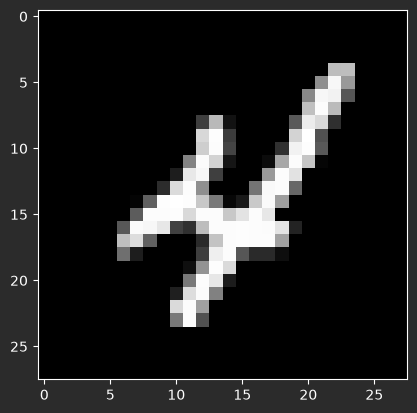

Label: 4


In [9]:
plt.imshow(image, cmap='gray')
plt.show()
print(f'Label: {label}')

In [11]:
train_loader = torch.utils.data.DataLoader(
    dataset=mnist_train,
    batch_size=100,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    dataset=mnist_test,
    batch_size=100,
    shuffle=False
)

In [12]:
data_train_iter = iter(train_loader)
images, labels = next(data_train_iter)
print(images.shape)
print(labels.shape)

torch.Size([100, 1, 28, 28])
torch.Size([100])


In [14]:
x = images.view(-1, 28*28)
print(x.shape)

torch.Size([100, 784])


$$
y_1 = \sum_i{x_iw_{i,1}} = b_1
$$

$$
y= zW + b
$$

In [15]:
W = torch.randn(784,10)/ np.sqrt(784) # Xavier initialization

$$
\sigma = \frac{1}{\sqrt{784}}
$$

[XE VS HE habr](https://habr.com/ru/articles/932852/)

[Xavier in Geekforgeeks](https://www.geeksforgeeks.org/deep-learning/xavier-initialization/)

[XE VS HE Medium](https://medium.com/thedeephub/he-and-xavier-weight-initialization-functions-acedc5322ce5)

In [18]:
W.requires_grad = True
b = torch.zeros(10, requires_grad=True)

# Forward propagation
$$
y= zW + b
$$

In [19]:
y = torch.matmul(x, W) + b
print(y[0, :]) # logits

tensor([ 0.3184,  0.7739,  0.1844,  0.2710, -0.2170, -0.2534,  0.1189, -0.0263,
        -0.0583, -0.1184], grad_fn=<SelectBackward0>)


# Softmax
$$
P_i = \frac{e^{z_i}}{\sum_{j=1}^ke^{z_j}}
$$

In [20]:
# py_eq = torch.exp(y)/torch.sum(torch.exp(y), dim=1, keepdim=True)
# print(py_eq[0])

tensor([0.1188, 0.1874, 0.1039, 0.1133, 0.0696, 0.0671, 0.0973, 0.0842, 0.0815,
        0.0768], grad_fn=<SelectBackward0>)


In [21]:
py = F.softmax(y, dim=1)
print(py[0])

tensor([0.1188, 0.1874, 0.1039, 0.1133, 0.0696, 0.0671, 0.0973, 0.0842, 0.0815,
        0.0768], grad_fn=<SelectBackward0>)


# Cross Entropy
$$
H_y(y) = -\sum_{i=1}^{C}{y_i \log(\hat{y}_i)}
$$

$$
L = -ln(P_k)
$$


$$
L = -\frac{1}{N}\sum_{n=1}^{N}\sum_{i=1}^{C} y_{n,i}\log(\hat{y}_{n,i})
$$


$$
L = -\sum_{i=1}^{C} y_i \log\left(\frac{e^{z_i}}{\sum_{j=1}^{C}e^{z_j}}\right)
$$



In [22]:
# cross_entropy_eq = torch.mean(-torch.log(py)[range(labels.shape[0]), labels])
# print(cross_entropy_eq)

tensor(2.3481, grad_fn=<MeanBackward0>)


In [23]:
cross_entropy = F.cross_entropy(y, labels)
print(cross_entropy)

tensor(2.3481, grad_fn=<NllLossBackward0>)


# Оптимизатор
### SGD - Stochastic Gradient Descent - Стохастический градиентный спуск

In [24]:
optimizer = torch.optim.SGD([W, b], lr=0.1)
cross_entropy.backward()
b.grad

tensor([-0.0418,  0.0367, -0.0079,  0.0113,  0.0304, -0.0044,  0.0404, -0.0598,
         0.0034, -0.0082])

In [25]:
optimizer.step()
b

tensor([ 0.0042, -0.0037,  0.0008, -0.0011, -0.0030,  0.0004, -0.0040,  0.0060,
        -0.0003,  0.0008], requires_grad=True)

In [26]:
print(b.grad)
optimizer.zero_grad()
print(b.grad)

tensor([-0.0418,  0.0367, -0.0079,  0.0113,  0.0304, -0.0044,  0.0404, -0.0598,
         0.0034, -0.0082])
None


In [28]:
print(len(train_loader))
for images, labels in tqdm(train_loader):
    optimizer.zero_grad()
    x = images.view(-1, 28*28)
    y = torch.matmul(x, W) + b
    cross_entropy = F.cross_entropy(y, labels)

    cross_entropy.backward()
    optimizer.step()

600


100%|██████████| 600/600 [00:08<00:00, 70.58it/s]


In [29]:
correct = 0
total = len(mnist_test)
with torch.no_grad():
    for images, labels in tqdm(test_loader):
        x = images.view(-1, 28*28)
        y = torch.matmul(x, W) + b
        pred = torch.argmax(y, dim=1)
        correct += torch.sum(pred == labels).float()
print(correct / total)

100%|██████████| 100/100 [00:02<00:00, 48.32it/s]

tensor(0.9034)


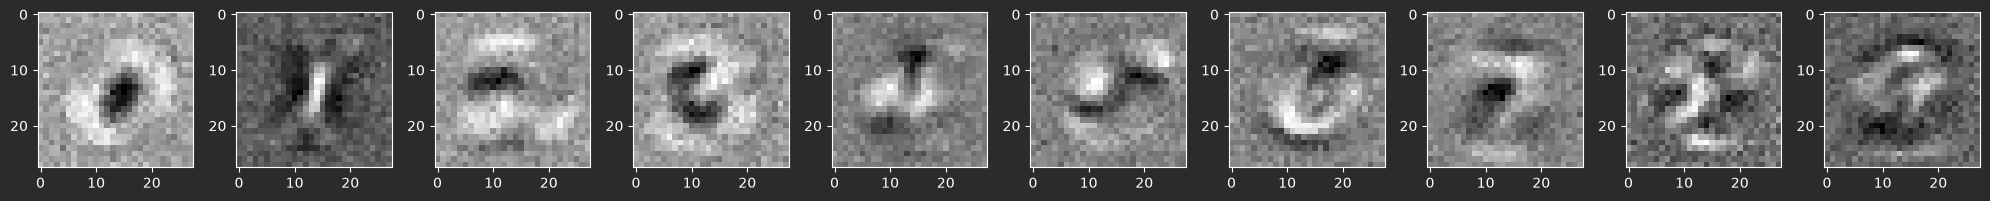

In [30]:
fig, ax = plt.subplots(1, 10, figsize=(20, 5))
for i in range(10):
    ax[i].imshow(W[:, i].detach().view(28, 28), cmap='gray')
    plt.tight_layout()
plt.show()